# Model Selection Project

1. Import library

- train_test_split, make_pipeline: membagi data dan merangkai langkah pemrosesan.
- LinearRegression, Ridge, RidgeCV, Lasso, LassoCV: model regresi biasa dan yang diregularisasi.
- StandardScaler, OneHotEncoder: penyamaan skala dan encoding kategori.
= root_mean_squared_error, mean_absolute_error, r2_score: metrik evaluasi.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, RidgeCV, Lasso, LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score
from category_encoders import OneHotEncoder


2. Memuat data dan menyiapkan fitur

- clean_files("./data/buenos-aires-real-estate-*.csv"): data bersih dari wrangle.py.
- target = "price_aprox_usd" dan feature = [col for col in df.columns if col not in target]: target harga dan 4 fitur (luas, lat, lon, neighborhood).
- X = df[feature], y = df[target]: shape X (6.247, 4) dan y (6.247,).

In [3]:
# Import our cleaning function
from wrangle import clean_files

# Load data
df = clean_files("./data/buenos-aires-real-estate-*.csv")   # <--- "./data/buenos-aires-real-estate-*.csv"

# Define target and features
target = "price_aprox_usd"
feature = [col for col in df.columns if col not in target]

# Split into features and target
X = df[feature] #<--- feature matrix
y = df[target] # <--- target vector

print(f"Features shape: {X.shape}")
print(f"Target shape: {y.shape}")

Features shape: (6247, 4)
Target shape: (6247,)


3. Train-test split

- train_test_split(X, y, test_size=0.2, random_state=42): 4.997 data latih dan 1.250 data uji.

In [4]:
X_train_4, X_test_4, y_train_4, y_test_4 = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Training rows: {len(X_train_4)}")
print(f"Testing rows: {len(X_test_4)}")

Training rows: 4997
Testing rows: 1250


4. Fungsi get_rmse_4

- model.predict(X) lalu root_mean_squared_error(y_true, y_pred): fungsi pembantu untuk menghitung RMSE model mana pun, supaya kode tidak berulang.

In [5]:
def get_rmse_4(model, X, y_true):
    """
    Calculate RMSE for a given model and dataset.

    Parameters:
    -----------
    model : fitted sklearn model or pipeline
    X : features (DataFrame or array)
    y_true : true target values

    Returns:
    --------
    float : RMSE value
    """
    y_pred = model.predict(X)  # <--- X
    rmse = root_mean_squared_error(y_true, y_pred) # <--- y_true, y_pred
    return rmse

# Test the function
print("Function created successfully!")

Function created successfully!


5. Baseline

- y_train_4.mean(): rata-rata harga data latih sebagai prediksi konstan.
- RMSE baseline: latih 59.700,25 USD dan uji 57.576,13 USD.

In [6]:
# Calculate mean
y_mean_4 = y_train_4.mean()

# Create baseline predictions
y_pred_baseline_train = [y_mean_4] * len(y_train_4)
y_pred_baseline_test = [y_mean_4] * len(y_test_4)

# Calculate RMSE
rmse_base_train = root_mean_squared_error(y_train_4, y_pred_baseline_train)  # root_mean_squared_error(y_train_4, y_pred_baseline_train)
rmse_base_test = root_mean_squared_error(y_test_4, y_pred_baseline_test)  # root_mean_squared_error(y_test_4, y_pred_baseline_test)

print(f"Baseline Train RMSE: ${rmse_base_train:,.2f}")
print(f"Baseline Test RMSE: ${rmse_base_test:,.2f}")

Baseline Train RMSE: $59,700.25
Baseline Test RMSE: $57,576.13


6. Regresi linier biasa

- make_pipeline(OneHotEncoder(use_cat_names=True), StandardScaler(), LinearRegression()): encoding, scaling, dan model dalam satu rangkaian.
- RMSE: latih 34.200,43 USD dan uji 33.088,37 USD.

In [7]:
model_linear_4 = make_pipeline(
    OneHotEncoder(use_cat_names=True),
    StandardScaler(),
    LinearRegression()
)

model_linear_4.fit(X_train_4, y_train_4)  # X_train_4, y_train_4

rmse_linear_train = get_rmse_4(model_linear_4, X_train_4, y_train_4)  # model_linear_4, X_train_4, y_train_4
rmse_linear_test = get_rmse_4(model_linear_4, X_test_4, y_test_4)  # model_linear_4, X_test_4, y_test_4

print(f"Linear Regression Train RMSE: ${rmse_linear_train:,.2f}")
print(f"Linear Regression Test RMSE: ${rmse_linear_test:,.2f}")

Linear Regression Train RMSE: $34,200.43
Linear Regression Test RMSE: $33,088.37


7. Rentang alpha

- np.logspace(-2, 4, 100): 100 nilai alpha dari 0,01 sampai 10.000 dengan skala logaritmik, dipakai sebagai kandidat untuk RidgeCV.

In [8]:
np.logspace(-2, 4, 100)

array([1.00000000e-02, 1.14975700e-02, 1.32194115e-02, 1.51991108e-02,
       1.74752840e-02, 2.00923300e-02, 2.31012970e-02, 2.65608778e-02,
       3.05385551e-02, 3.51119173e-02, 4.03701726e-02, 4.64158883e-02,
       5.33669923e-02, 6.13590727e-02, 7.05480231e-02, 8.11130831e-02,
       9.32603347e-02, 1.07226722e-01, 1.23284674e-01, 1.41747416e-01,
       1.62975083e-01, 1.87381742e-01, 2.15443469e-01, 2.47707636e-01,
       2.84803587e-01, 3.27454916e-01, 3.76493581e-01, 4.32876128e-01,
       4.97702356e-01, 5.72236766e-01, 6.57933225e-01, 7.56463328e-01,
       8.69749003e-01, 1.00000000e+00, 1.14975700e+00, 1.32194115e+00,
       1.51991108e+00, 1.74752840e+00, 2.00923300e+00, 2.31012970e+00,
       2.65608778e+00, 3.05385551e+00, 3.51119173e+00, 4.03701726e+00,
       4.64158883e+00, 5.33669923e+00, 6.13590727e+00, 7.05480231e+00,
       8.11130831e+00, 9.32603347e+00, 1.07226722e+01, 1.23284674e+01,
       1.41747416e+01, 1.62975083e+01, 1.87381742e+01, 2.15443469e+01,
      

8. Ridge dengan cross-validation

- RidgeCV(alphas=np.logspace(-2, 4, 100)) dalam pipeline: mencari alpha terbaik otomatis.
named_steps["ridgecv"].alpha_: alpha terpilih 43,29.
- RMSE: 
    - latih 34.203,95 USD 
    - uji 33.071,27 USD.

In [9]:
model_ridge_4 = make_pipeline(
    OneHotEncoder(use_cat_names=True),  # True
    StandardScaler(),
    RidgeCV(alphas=np.logspace(-2, 4, 100))  # np.logspace(-2, 4, 100)
)

model_ridge_4.fit(X_train_4, y_train_4)  # X_train_4, y_train_4

rmse_ridge_train = get_rmse_4(model_ridge_4, X_train_4, y_train_4)  # model_ridge_4, X_train_4, y_train_4
rmse_ridge_test = get_rmse_4(model_ridge_4, X_test_4, y_test_4)  # model_ridge_4, X_test_4, y_test_4

# Extract the tuned alpha value
alpha_ridge_chosen = model_ridge_4.named_steps["ridgecv"].alpha_
print(f"Best Ridge alpha: {alpha_ridge_chosen:.6f}")
print(f"Ridge Train RMSE: ${rmse_ridge_train:,.2f}")
print(f"Ridge Test RMSE: ${rmse_ridge_test:,.2f}")

Best Ridge alpha: 43.287613
Ridge Train RMSE: $34,203.95
Ridge Test RMSE: $33,071.27


9. Lasso dengan cross-validation

- LassoCV(alphas=np.logspace(-4, 2, 100), max_iter=10000): kandidat alpha 0,0001 sampai 100.
Alpha terpilih 32,75.
- RMSE: 
    - latih 34.203,20 USD 
    - uji 33.069,18 USD.

In [10]:
model_lasso_4 = make_pipeline(
    OneHotEncoder(use_cat_names=True),  # True
    StandardScaler(),
    LassoCV(alphas=np.logspace(-4, 2, 100), max_iter=10000)  # np.logspace(-4, 2, 100)
)

model_lasso_4.fit(X_train_4, y_train_4)  # X_train_4, y_train_4

rmse_lasso_train = get_rmse_4(model_lasso_4, X_train_4, y_train_4)  # model_lasso_4, X_train_4, y_train_4
rmse_lasso_test = get_rmse_4(model_lasso_4, X_test_4, y_test_4)  # model_lasso_4, X_test_4, y_test_4

# Extract the tuned alpha value
alpha_lasso_chosen = model_lasso_4.named_steps["lassocv"].alpha_
print(f"Best Lasso alpha: {alpha_lasso_chosen:.6f}")
print(f"Lasso Train RMSE: ${rmse_lasso_train:,.2f}")
print(f"Lasso Test RMSE: ${rmse_lasso_test:,.2f}")

Best Lasso alpha: 32.745492
Lasso Train RMSE: $34,203.20
Lasso Test RMSE: $33,069.18


10. Tabel perbandingan

- Dictionary data_4 menjadi DataFrame df_results_4, dengan kolom Gap = Test_RMSE - Train_RMSE (selisih uji dan latih), lalu set_index("Model").
- Hasil RMSE uji: 
    - Baseline 57.576, 
    - Linear 33.088, 
    - Ridge 33.071, 
    - Lasso 33.069. 
- Ketiga model regresi sangat mirip dan jauh lebih baik dari baseline.

In [11]:
# Build Results Table
data_4 = {
    "Model": ["Baseline", "Linear Regression", "Ridge (CV-tuned)", "Lasso (CV-tuned)"],
    "Train_RMSE": [
        rmse_base_train,
        rmse_linear_train,  # rmse_linear_train
        rmse_ridge_train,  # rmse_ridge_train
        rmse_lasso_train   # rmse_lasso_train
    ],
    "Test_RMSE": [
        rmse_base_test,
        rmse_linear_test,  # rmse_linear_test
        rmse_ridge_test,  # rmse_ridge_test
        rmse_lasso_test   # rmse_lasso_test
    ]
}

df_results_4 = pd.DataFrame(data_4)

# Calculate Generalization Gap
df_results_4["Gap"] = df_results_4["Test_RMSE"] - df_results_4["Train_RMSE"]

# Set Model as index for better display
df_results_4 = df_results_4.set_index("Model")

print("\n" + "="*60)
print("MODEL COMPARISON TABLE")
print("="*60)
print(df_results_4.round(2))
print("="*60)


MODEL COMPARISON TABLE
                   Train_RMSE  Test_RMSE      Gap
Model                                            
Baseline             59700.25   57576.13 -2124.12
Linear Regression    34200.43   33088.37 -1112.06
Ridge (CV-tuned)     34203.95   33071.27 -1132.68
Lasso (CV-tuned)     34203.20   33069.18 -1134.01


11. Grafik prediksi vs aktual

- model_lasso_4.predict(X_test_4): prediksi Lasso pada data uji.
- ax.scatter(y_test_4, y_pred_lasso_4) dan ax.plot(ideal_line, ideal_line, color="red", linestyle="--"): sebaran prediksi terhadap harga asli, dengan garis merah sebagai prediksi sempurna.

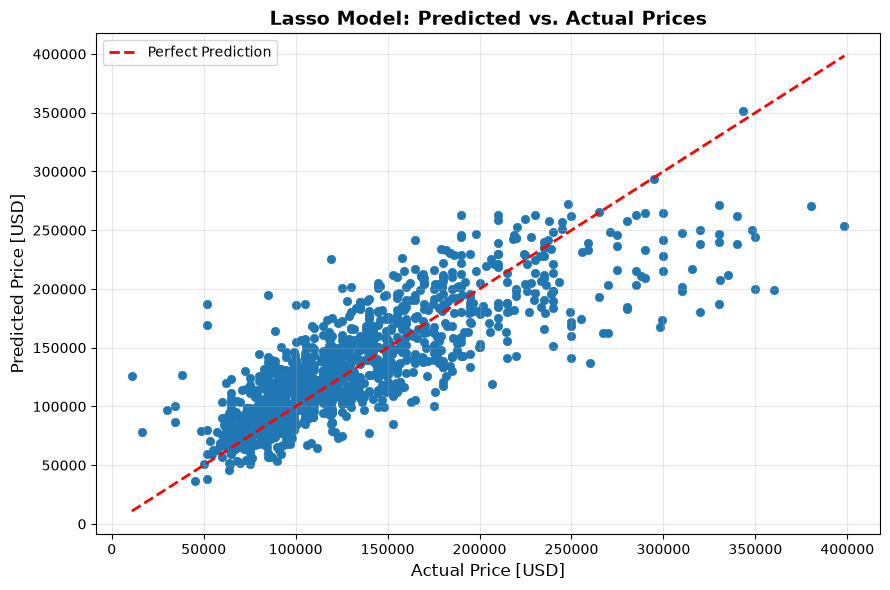

In [12]:
y_pred_lasso_4 = model_lasso_4.predict(X_test_4)

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(y_test_4, y_pred_lasso_4, linewidth=0.5)

ideal_line = np.linspace(y_test_4.min(), y_test_4.max(), 100)
ax.plot(ideal_line, ideal_line, color="red", linestyle="--", linewidth=2, label="Perfect Prediction")

ax.set_xlabel("Actual Price [USD]", fontsize=12)
ax.set_ylabel("Predicted Price [USD]", fontsize=12)
ax.set_title("Lasso Model: Predicted vs. Actual Prices", fontsize=14, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

12. Grafik residual

- residuals_4 = y_test_4 - y_pred_lasso_4: selisih harga asli dan prediksi.
- ax_res.scatter(...) dan axhline(y=0): sebaran residual terhadap prediksi untuk mengecek asumsi model.

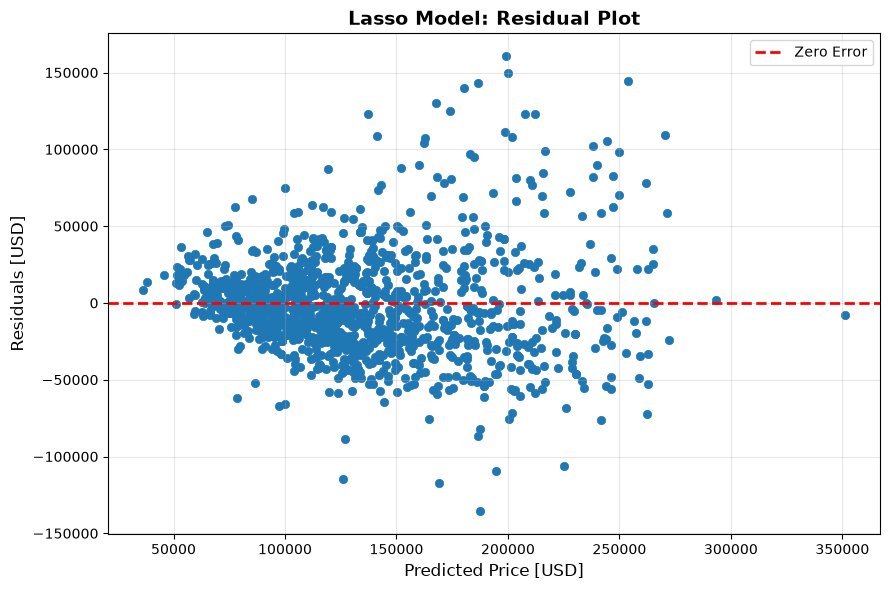

In [13]:
residuals_4 = y_test_4 - y_pred_lasso_4

fig_res, ax_res = plt.subplots(figsize=(9, 6))
ax_res.scatter(y_pred_lasso_4, residuals_4, linewidth=0.5)
ax_res.axhline(y=0, color='r', linestyle='--', linewidth=2, label='Zero Error')
ax_res.set_xlabel("Predicted Price [USD]", fontsize=12)
ax_res.set_ylabel("Residuals [USD]", fontsize=12)
ax_res.set_title("Lasso Model: Residual Plot", fontsize=14, fontweight='bold')
ax_res.legend(fontsize=10)
ax_res.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

13. Koefisien Lasso

- named_steps["lassocv"].coef_ dan named_steps["onehotencoder"].get_feature_names_out(): koefisien dan nama fiturnya, digabung menjadi pd.Series.
- Total 59 fitur, 58 bukan nol.
- Paling menaikkan harga: luas (+40.346), Puerto Madero (+9.794), Palermo (+9.684), lat (+8.837), Belgrano (+7.270).
- Paling menurunkan harga: Balvanera (-5.421), Boca (-4.734), Once (-4.528), Congreso (-3.353), Constitución (-2.737).

In [14]:
# Extract from pipeline
coefs_4 = model_lasso_4.named_steps["lassocv"].coef_  # .coef_
feature_names_4 = model_lasso_4.named_steps["onehotencoder"].get_feature_names_out()  # .get_feature_names_out()

feat_imp_4 = pd.Series(coefs_4, index=feature_names_4)  # coefs_4, index=feature_names_4

print(f"Total features: {len(feat_imp_4)}")
print(f"Non-zero features: {(feat_imp_4 != 0).sum()}")
print("\nTop 5 positive coefficients:")
print(feat_imp_4.nlargest(5))
print("\nTop 5 negative coefficients:")
print(feat_imp_4.nsmallest(5))

Total features: 59
Non-zero features: 58

Top 5 positive coefficients:
surface_covered_in_m2         40346.180348
neighborhood_Puerto Madero     9793.898166
neighborhood_Palermo           9684.053726
lat                            8837.497355
neighborhood_Belgrano          7270.101180
dtype: float64

Top 5 negative coefficients:
neighborhood_Balvanera      -5420.759156
neighborhood_Boca           -4734.035389
neighborhood_Once           -4527.997089
neighborhood_Congreso       -3353.222368
neighborhood_Constitución   -2736.586612
dtype: float64


14. Fitur yang dibuang Lasso

- (feat_imp_4 == 0).sum(): Lasso hanya membuang 1 dari 59 fitur (1,7%).

In [15]:
zero_features_4 = ((feat_imp_4 == 0).sum())  # (feat_imp_4 == 0).sum()
total_features_4 = len(feat_imp_4)
percent_eliminated_4 = (zero_features_4 / total_features_4) * 100

print(f"Lasso eliminated {zero_features_4} out of {total_features_4} features.")
print(f"Percentage eliminated: {percent_eliminated_4:.1f}%")

Lasso eliminated 1 out of 59 features.
Percentage eliminated: 1.7%


15. Grafik 10 fitur terpenting

- feat_imp_4.sort_values(key=abs).tail(10).plot(kind="barh"): 10 koefisien terbesar berdasarkan nilai absolut.

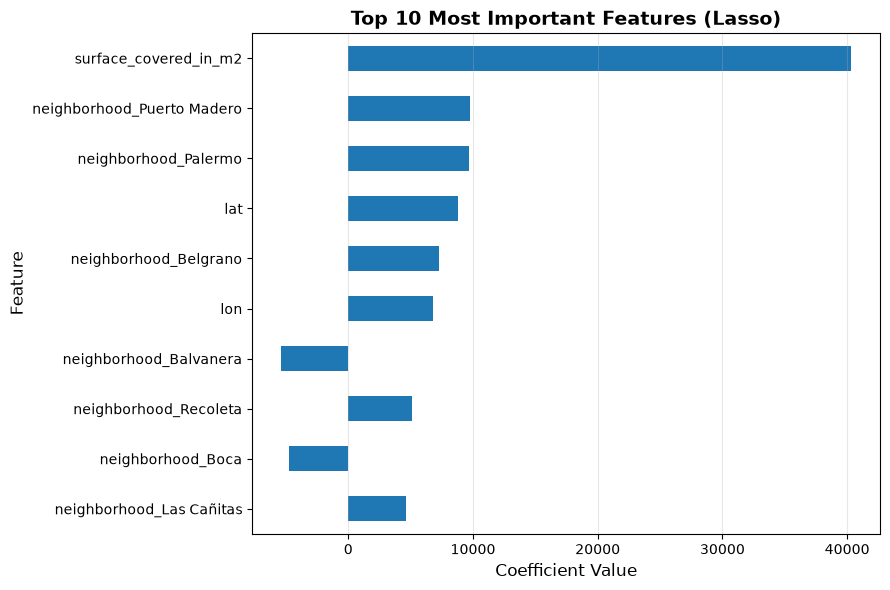

In [16]:
fig_feat, ax_feat = plt.subplots(figsize=(9, 6))
feat_imp_4.sort_values(key=abs).tail(10).plot(kind="barh", ax=ax_feat)
ax_feat.set_title("Top 10 Most Important Features (Lasso)", fontsize=14, fontweight='bold')
ax_feat.set_xlabel("Coefficient Value", fontsize=12)
ax_feat.set_ylabel("Feature", fontsize=12)
ax_feat.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

16. Fitur paling berpengaruh

- idxmax() dan max(): fitur dengan koefisien positif terbesar adalah surface_covered_in_m2 (40.346,18).

In [17]:
top_feature_4 = feat_imp_4.idxmax()
top_coefficient_4 = feat_imp_4.max()

print(f"The most influential positive feature is: {top_feature_4}")
print(f"Its coefficient is: ${top_coefficient_4:,.2f}")

The most influential positive feature is: surface_covered_in_m2
Its coefficient is: $40,346.18


17. Laporan pemilihan model

- df_results_4["Test_RMSE"].idxmin(): memilih model dengan RMSE uji terendah, yaitu Lasso (CV-tuned).
- f-string multi-baris: laporan otomatis berisi perbandingan performa, analisis generalisasi, interpretabilitas, dan rekomendasi. 

In [20]:
# Find which model has the lowest test RMSE
best_model = df_results_4["Test_RMSE"].idxmin()  # df_results_4["Test_RMSE"].idxmin()

recommendation = f"""
=================================================================
FINAL MODEL SELECTION REPORT
=================================================================

EXECUTIVE SUMMARY:
Based on comprehensive evaluation, I recommend the {best_model} model
for production deployment.

PERFORMANCE COMPARISON:
- Baseline Test RMSE: ${rmse_base_test:,.2f}
- Linear Regression Test RMSE: ${rmse_linear_test:,.2f}
- Ridge (CV-tuned) Test RMSE: ${rmse_ridge_test:,.2f}
- Lasso (CV-tuned) Test RMSE: ${rmse_lasso_test:,.2f}

GENERALIZATION ANALYSIS:
The {best_model} model shows the best balance between low test error
and minimal generalization gap, indicating it will perform
reliably on new, unseen properties.

INTERPRETABILITY:
The Lasso model eliminated {zero_features_4} out of
{total_features_4} features ({percent_eliminated_4:.1f}%),
making it highly interpretable for business stakeholders.

KEY PREDICTORS:
The most influential feature is: {top_feature_4}

RECOMMENDATION:
I recommend deploying the {best_model} model because:
1. consider test RMSE performance
2. consider generalization gap
3. consider interpretability or simplicity

=================================================================
"""

print(recommendation)


FINAL MODEL SELECTION REPORT

EXECUTIVE SUMMARY:
Based on comprehensive evaluation, I recommend the Lasso (CV-tuned) model
for production deployment.

PERFORMANCE COMPARISON:
- Baseline Test RMSE: $57,576.13
- Linear Regression Test RMSE: $33,088.37
- Ridge (CV-tuned) Test RMSE: $33,071.27
- Lasso (CV-tuned) Test RMSE: $33,069.18

GENERALIZATION ANALYSIS:
The Lasso (CV-tuned) model shows the best balance between low test error
and minimal generalization gap, indicating it will perform
reliably on new, unseen properties.

INTERPRETABILITY:
The Lasso model eliminated 1 out of
59 features (1.7%),
making it highly interpretable for business stakeholders.

KEY PREDICTORS:
The most influential feature is: surface_covered_in_m2

RECOMMENDATION:
I recommend deploying the Lasso (CV-tuned) model because:
1. consider test RMSE performance
2. consider generalization gap
3. consider interpretability or simplicity




Kesimpulan singkat

- Project ini membandingkan empat model untuk memprediksi harga apartemen di Buenos Aires: 
    - baseline (rata-rata), 
    - regresi linier, 
    - Ridge (alpha 43,29), dan 
    - Lasso (alpha 32,75), 
- dengan alpha dipilih lewat cross-validation. 
- Ketiga model regresi mengurangi RMSE uji dari sekitar 57.576 USD (baseline) menjadi sekitar 33.070 USD, tetapi perbedaan di antara mereka sangat kecil (hanya sekitar 20 USD). 
- Lasso secara teknis terbaik (33.069 USD) dan dipilih sebagai rekomendasi. 
- Karena datanya “tinggi” (banyak baris, sedikit fitur), regularisasi hampir tidak memberi keuntungan dibanding regresi linier biasa. 
- Faktor harga yang paling kuat adalah luas bangunan, lalu lokasi premium seperti Puerto Madero, Palermo, dan Belgrano. 
- Sebaliknya Balvanera, Boca, dan Once cenderung menurunkan harga. 
- Residual berbentuk corong menandakan model linier punya keterbatasan, dan galat sekitar 26% membuat kesiapan untuk produksi perlu dipertimbangkan hati-hati.

Catatan: Pemilihan Lasso berdasarkan selisih RMSE yang sangat kecil, jadi secara praktis ketiga model setara. 